# CBIS-DDSM Mammography — Multi-Output Clinical Report Model
CLIP vision encoder + 6 classification heads → structured radiologist-style report

**Predicted fields per image:**
- Pathology (BENIGN / MALIGNANT)
- BI-RADS assessment (0–6)
- Subtlety (1–5)
- Breast density (1–4)
- Mass shape
- Mass margins

In [12]:
import os, warnings
os.environ['TRANSFORMERS_OFFLINE'] = '1'
os.environ['HF_DATASETS_OFFLINE'] = '1'
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
from pathlib import Path
from datetime import datetime
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from transformers import CLIPModel, CLIPProcessor
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, roc_auc_score,
    confusion_matrix, classification_report
)
warnings.filterwarnings('ignore')

# ── GPU setup (RTX 4050 optimised) ───────────────────────────────────────
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
    print(f"GPU  : {torch.cuda.get_device_name(0)}")
    print(f"VRAM : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"Device : {DEVICE}")
print(f"PyTorch: {torch.__version__}")

GPU  : NVIDIA GeForce RTX 4050 Laptop GPU
VRAM : 6.4 GB
Device : cuda
PyTorch: 2.6.0+cu124


## 1 — Config

In [13]:
# ── Local project paths (relative — works inside mammography-clip/) ───────
BASE      = './data'
CSV_DIR   = f'{BASE}/csv'
JPEG_ROOT = f'{BASE}/jpeg'
SAVE_DIR  = './output'
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs('./new_images', exist_ok=True)

CONFIG = {
    'model_name'             : 'openai/clip-vit-base-patch32',
    'batch_size'             : 8,       # safe for 6 GB VRAM (RTX 4050)
    'num_epochs'             : 20,  # bumped from 15 to compensate for no 3x caption augmentation
    'lr'                     : 1e-5,
    'weight_decay'           : 0.01,
    'max_length'             : 77,
    'num_workers'            : 0,       # MUST be 0 on Windows
    'patience'               : 5,
    'freeze_vision'          : False,
    'unfreeze_last_n_vision' : 4,
    'k_folds'                : 3,
    
}
print("Config:", CONFIG)

Config: {'model_name': 'openai/clip-vit-base-patch32', 'batch_size': 8, 'num_epochs': 20, 'lr': 1e-05, 'weight_decay': 0.01, 'max_length': 77, 'num_workers': 0, 'patience': 5, 'freeze_vision': False, 'unfreeze_last_n_vision': 4, 'k_folds': 3}


## 2 — Load CSVs

In [14]:
mass_train = pd.read_csv(f'{CSV_DIR}/mass_case_description_train_set.csv')
mass_test  = pd.read_csv(f'{CSV_DIR}/mass_case_description_test_set.csv')
calc_train = pd.read_csv(f'{CSV_DIR}/calc_case_description_train_set.csv')
calc_test  = pd.read_csv(f'{CSV_DIR}/calc_case_description_test_set.csv')

# Normalise column name (calc files use a space, mass files use underscore)
for df in [calc_train, calc_test]:
    df.rename(columns={'breast density': 'breast_density'}, inplace=True)

# Collapse BENIGN_WITHOUT_CALLBACK → BENIGN everywhere
for df in [mass_train, mass_test, calc_train, calc_test]:
    df['pathology'] = df['pathology'].replace('BENIGN_WITHOUT_CALLBACK', 'BENIGN')

print(f"mass_train : {len(mass_train):,} rows")
print(f"mass_test  : {len(mass_test):,} rows")
print(f"calc_train : {len(calc_train):,} rows")
print(f"calc_test  : {len(calc_test):,} rows")
print("\nMass train columns:", list(mass_train.columns))

mass_train : 1,318 rows
mass_test  : 378 rows
calc_train : 1,546 rows
calc_test  : 326 rows

Mass train columns: ['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']


## 3 — JPEG path cache

In [15]:
print("Building JPEG path cache...")
jpeg_cache = {}
for uid_folder in os.listdir(JPEG_ROOT):
    full_path = os.path.join(JPEG_ROOT, uid_folder)
    if os.path.isdir(full_path):
        files = [f for f in os.listdir(full_path) if f.endswith('.jpg')]
        if files:
            jpeg_cache[uid_folder] = os.path.join(full_path, files[0])
print(f"Cached {len(jpeg_cache):,} JPEG paths")

def resolve_path(csv_path):
    """Map a DICOM-style CSV path to the actual JPEG on disk via the UID cache."""
    parts = str(csv_path).split('/')
    for idx in [3, 2]:
        if len(parts) > idx:
            result = jpeg_cache.get(parts[idx])
            if result:
                return result
    return None

for name, df in [('mass_train', mass_train), ('mass_test', mass_test),
                 ('calc_train', calc_train),  ('calc_test', calc_test)]:
    found = df['cropped image file path'].apply(resolve_path).notna().sum()
    print(f"  {name:12s}: {found}/{len(df)} paths resolved")

Building JPEG path cache...
Cached 6,774 JPEG paths
  mass_train  : 1318/1318 paths resolved
  mass_test   : 378/378 paths resolved
  calc_train  : 1545/1546 paths resolved
  calc_test   : 326/326 paths resolved


## 4 — Build dataframes with ALL clinical labels

In [16]:
def build_df(df, lesion_type):
    """
    Build a dataframe that keeps ALL clinical label columns needed
    for multi-output prediction, plus the image path.
    """
    density_col = 'breast_density' if 'breast_density' in df.columns else 'breast density'
    records = []

    for _, row in df.iterrows():
        img_path = (resolve_path(row.get('cropped image file path'))
                 or resolve_path(row.get('image file path')))
        if img_path is None:
            continue

        def g(col, default=None):
            v = row.get(col)
            return str(v).strip() if pd.notna(v) else default

        pathology  = g('pathology', 'BENIGN')
        assessment = g('assessment', None)
        subtlety   = g('subtlety',   None)
        density    = g(density_col,  None)
        pid        = g('patient_id', 'unknown')
        laterality = g('left or right breast', 'unspecified')
        view       = g('image view', 'unspecified')
        ab_type    = g('abnormality type', lesion_type)

        # Mass-specific fields
        mass_shape   = g('mass shape',   None) if lesion_type == 'mass' else None
        mass_margins = g('mass margins', None) if lesion_type == 'mass' else None
        calc_type    = g('calc type',    None) if lesion_type == 'calc' else None
        calc_dist    = g('calc distribution', None) if lesion_type == 'calc' else None

        records.append({
            'patient_id'  : pid,
            'image_path'  : img_path,
            'label'       : 1 if pathology == 'MALIGNANT' else 0,
            'pathology'   : pathology,
            'assessment'  : assessment,
            'subtlety'    : subtlety,
            'breast_density': density,
            'mass_shape'  : mass_shape,
            'mass_margins': mass_margins,
            'calc_type'   : calc_type,
            'calc_distribution': calc_dist,
            'laterality'  : laterality,
            'view'        : view,
            'ab_type'     : ab_type,
            'lesion_type' : lesion_type,
        })

    return pd.DataFrame(records)


train_df = pd.concat([build_df(mass_train, 'mass'),
                      build_df(calc_train,  'calc')], ignore_index=True)
test_df  = pd.concat([build_df(mass_test,  'mass'),
                      build_df(calc_test,   'calc')], ignore_index=True)

# Remove conflicting pathology labels for same patient+laterality
def remove_conflicts(df, name):
    mask = (df.groupby(['patient_id', 'laterality'])['pathology']
              .transform('nunique') > 1)
    print(f"  Conflicts removed from {name}: {mask.sum()} rows")
    return df[~mask].reset_index(drop=True)

train_df = remove_conflicts(train_df, 'train')
test_df  = remove_conflicts(test_df,  'test')

print(f"\nTrain : {len(train_df):,} rows | {train_df['patient_id'].nunique()} patients")
print(f"Test  : {len(test_df):,}  rows | {test_df['patient_id'].nunique()} patients")
print(f"\nLabel distribution (train):")
print(train_df['pathology'].value_counts())
print(f"\nSample clinical data:")
print(train_df[['pathology','assessment','subtlety','breast_density','mass_shape','mass_margins']].head(3))

  Conflicts removed from train: 42 rows
  Conflicts removed from test: 14 rows

Train : 2,822 rows | 1242 patients
Test  : 690  rows | 345 patients

Label distribution (train):
pathology
BENIGN       1663
MALIGNANT    1159
Name: count, dtype: int64

Sample clinical data:
   pathology assessment subtlety breast_density  \
0  MALIGNANT          4        4              3   
1  MALIGNANT          4        4              3   
2     BENIGN          4        3              3   

                           mass_shape mass_margins  
0  IRREGULAR-ARCHITECTURAL_DISTORTION   SPICULATED  
1  IRREGULAR-ARCHITECTURAL_DISTORTION   SPICULATED  
2            ARCHITECTURAL_DISTORTION  ILL_DEFINED  


## 5 — Remove train/test patient overlap

In [17]:
overlap = set(train_df['patient_id']) & set(test_df['patient_id'])
if overlap:
    print(f"Removing {len(overlap)} overlapping patients from train_df")
    train_df = train_df[~train_df['patient_id'].isin(overlap)].reset_index(drop=True)

print(f"Train : {len(train_df):,} rows | {train_df['patient_id'].nunique()} patients")
print(f"Test  : {len(test_df):,}  rows | {test_df['patient_id'].nunique()} patients")

Removing 30 overlapping patients from train_df
Train : 2,743 rows | 1212 patients
Test  : 690  rows | 345 patients


## 6 — Fit label encoders on training data

In [18]:
# ── Fixed encoders for ordinal/known-range columns ───────────────────────
PATHOLOGY_MAP  = {'BENIGN': 0, 'MALIGNANT': 1}
ASSESSMENT_MAP = {'0':0,'1':1,'2':2,'3':3,'4':4,'5':5,'6':6}
SUBTLETY_MAP   = {'1':0,'2':1,'3':2,'4':3,'5':4}
DENSITY_MAP    = {'1':0,'2':1,'3':2,'4':3}

# ── Data-driven encoders for free-text categorical columns ────────────────
le_shape   = LabelEncoder()
le_margins = LabelEncoder()
le_calctype = LabelEncoder()
le_calcdist = LabelEncoder()

def safe_fit(le, series):
    """Fit LabelEncoder ignoring None/NaN, add 'unknown' class."""
    vals = [v for v in series.dropna() if v is not None]
    le.fit(list(set(vals)) + ['unknown'])
    return le

safe_fit(le_shape,   train_df['mass_shape'].dropna())
safe_fit(le_margins, train_df['mass_margins'].dropna())
safe_fit(le_calctype, train_df['calc_type'].dropna())
safe_fit(le_calcdist, train_df['calc_distribution'].dropna())

def encode_label(le, val, fallback=-1):
    """Encode a single value; return fallback if missing."""
    if val is None or (isinstance(val, float) and np.isnan(val)):
        return fallback
    try:
        return int(le.transform([str(val)])[0])
    except ValueError:
        try:
            return int(le.transform(['unknown'])[0])
        except:
            return fallback

N_SHAPE   = len(le_shape.classes_)
N_MARGINS = len(le_margins.classes_)
N_CALCTYPE = len(le_calctype.classes_)
N_CALCDIST = len(le_calcdist.classes_)

print(f"Mass shape classes   ({N_SHAPE})  : {list(le_shape.classes_)}")
print(f"Mass margin classes  ({N_MARGINS}): {list(le_margins.classes_)}")
print(f"Calc type classes    ({N_CALCTYPE}): {list(le_calctype.classes_[:5])}...")
print(f"Calc distrib classes ({N_CALCDIST}): {list(le_calcdist.classes_)}")

Mass shape classes   (19)  : [np.str_('ARCHITECTURAL_DISTORTION'), np.str_('ASYMMETRIC_BREAST_TISSUE'), np.str_('FOCAL_ASYMMETRIC_DENSITY'), np.str_('IRREGULAR'), np.str_('IRREGULAR-ARCHITECTURAL_DISTORTION'), np.str_('IRREGULAR-FOCAL_ASYMMETRIC_DENSITY'), np.str_('LOBULATED'), np.str_('LOBULATED-ARCHITECTURAL_DISTORTION'), np.str_('LOBULATED-IRREGULAR'), np.str_('LOBULATED-LYMPH_NODE'), np.str_('LOBULATED-OVAL'), np.str_('LYMPH_NODE'), np.str_('OVAL'), np.str_('OVAL-LYMPH_NODE'), np.str_('ROUND'), np.str_('ROUND-IRREGULAR-ARCHITECTURAL_DISTORTION'), np.str_('ROUND-LOBULATED'), np.str_('ROUND-OVAL'), np.str_('unknown')]
Mass margin classes  (16): [np.str_('CIRCUMSCRIBED'), np.str_('CIRCUMSCRIBED-ILL_DEFINED'), np.str_('CIRCUMSCRIBED-MICROLOBULATED'), np.str_('CIRCUMSCRIBED-OBSCURED'), np.str_('ILL_DEFINED'), np.str_('ILL_DEFINED-SPICULATED'), np.str_('MICROLOBULATED'), np.str_('MICROLOBULATED-ILL_DEFINED'), np.str_('MICROLOBULATED-ILL_DEFINED-SPICULATED'), np.str_('MICROLOBULATED-SPICU

## 7 — Multi-output model architecture

CLIP vision encoder (frozen except last 4 layers) + 6 independent classification heads:
- `head_pathology` → BENIGN / MALIGNANT
- `head_assessment` → BI-RADS 0–6
- `head_subtlety` → 1–5
- `head_density` → 1–4
- `head_shape` → mass shape categories
- `head_margins` → mass margin categories

In [19]:
from torchvision import transforms

train_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.3),
    transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
])

processor = CLIPProcessor.from_pretrained(CONFIG['model_name'])


class MammographyReportModel(nn.Module):
    """
    CLIP vision encoder backbone with 6 classification heads.
    Each head predicts one clinical field independently.
    """
    def __init__(self, clip_model_name, n_shape, n_margins, n_calctype, n_calcdist):
        super().__init__()
        clip = CLIPModel.from_pretrained(clip_model_name )
        self.vision_model      = clip.vision_model
        self.visual_projection = clip.visual_projection
        hidden = 512  # CLIP ViT-B/32 projection dim

        # Dropout for regularisation
        self.dropout = nn.Dropout(0.3)

        # 6 independent classification heads
        self.head_pathology   = nn.Linear(hidden, 2)          # BENIGN / MALIGNANT
        self.head_assessment  = nn.Linear(hidden, 7)          # BI-RADS 0-6
        self.head_subtlety    = nn.Linear(hidden, 5)          # 1-5
        self.head_density     = nn.Linear(hidden, 4)          # 1-4
        self.head_shape       = nn.Linear(hidden, n_shape)    # mass shape
        self.head_margins     = nn.Linear(hidden, n_margins)  # mass margins

        # Freeze all vision layers first
        for p in self.vision_model.parameters():
            p.requires_grad = False

        # Unfreeze last N transformer blocks
        N = CONFIG['unfreeze_last_n_vision']
        layers = self.vision_model.encoder.layers
        for layer in layers[-N:]:
            for p in layer.parameters():
                p.requires_grad = True

        # Always unfreeze projection
        for p in self.visual_projection.parameters():
            p.requires_grad = True

    def get_embedding(self, pixel_values):
        out = self.vision_model(pixel_values=pixel_values)
        emb = self.visual_projection(out.pooler_output)
        return self.dropout(emb)  # (B, 512)

    def forward(self, pixel_values):
        emb = self.get_embedding(pixel_values)
        return {
            'pathology'  : self.head_pathology(emb),
            'assessment' : self.head_assessment(emb),
            'subtlety'   : self.head_subtlety(emb),
            'density'    : self.head_density(emb),
            'shape'      : self.head_shape(emb),
            'margins'    : self.head_margins(emb),
        }


def build_model():
    model = MammographyReportModel(
        CONFIG['model_name'],
        n_shape=N_SHAPE,
        n_margins=N_MARGINS,
        n_calctype=N_CALCTYPE,
        n_calcdist=N_CALCDIST,
    )
    return model.to(DEVICE)


def build_optimizer(model):
    unfrozen_vision = [
        p for layer in model.vision_model.encoder.layers[-CONFIG['unfreeze_last_n_vision']:]
        for p in layer.parameters() if p.requires_grad
    ]
    return AdamW([
        {'params': unfrozen_vision,                               'lr': CONFIG['lr'] * 0.1},
        {'params': model.visual_projection.parameters(),          'lr': CONFIG['lr'] * 5},
        {'params': model.head_pathology.parameters(),             'lr': CONFIG['lr'] * 10},
        {'params': model.head_assessment.parameters(),            'lr': CONFIG['lr'] * 10},
        {'params': model.head_subtlety.parameters(),              'lr': CONFIG['lr'] * 10},
        {'params': model.head_density.parameters(),               'lr': CONFIG['lr'] * 10},
        {'params': model.head_shape.parameters(),                 'lr': CONFIG['lr'] * 10},
        {'params': model.head_margins.parameters(),               'lr': CONFIG['lr'] * 10},
    ], weight_decay=CONFIG['weight_decay'])


print("Model architecture ready.")
_tmp = build_model()
total = sum(p.numel() for p in _tmp.parameters())
train_params = sum(p.numel() for p in _tmp.parameters() if p.requires_grad)
print(f"Total params   : {total:,}")
print(f"Trainable      : {train_params:,}")
del _tmp
torch.cuda.empty_cache()

Model architecture ready.


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 49759.54it/s]


Total params   : 87,876,405
Trainable      : 28,771,893


## 8 — Dataset & DataLoader (multi-label)

In [20]:

# Stronger augmentation to compensate for single-caption dataset (original used 3x captions)
from torchvision import transforms
import torchvision.transforms.functional as TF
import random

class MammographyAugment:
    """
    Mammography-specific augmentation.
    - Removed saturation/hue (useless on grayscale mammograms)
    - Added shear (mimics compression paddle variation)
    - Added gaussian noise (mimics detector noise)
    - Added gamma correction (mimics exposure variation)
    """
    def __init__(self):
        self.geometric = transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.3),
            transforms.RandomRotation(degrees=20),
            transforms.RandomResizedCrop(224, scale=(0.85, 1.0)),
            transforms.RandomAffine(
                degrees=0,
                translate=(0.08, 0.08),
                shear=5,              # mimics tissue compression variation
            ),
        ])
        self.intensity = transforms.Compose([
            transforms.ColorJitter(
                brightness=0.35,
                contrast=0.45,
                saturation=0.0,       # removed — no effect on grayscale
                hue=0.0,              # removed — no effect on grayscale
            ),
        ])

    def gaussian_noise(self, img, std=0.015):
        tensor = TF.to_tensor(img)
        noise  = torch.randn_like(tensor) * std
        tensor = torch.clamp(tensor + noise, 0.0, 1.0)
        return TF.to_pil_image(tensor)

    def random_gamma(self, img):
        gamma  = random.uniform(0.8, 1.25)
        tensor = TF.to_tensor(img)
        tensor = torch.clamp(tensor ** gamma, 0.0, 1.0)
        return TF.to_pil_image(tensor)

    def __call__(self, img):
        img = self.geometric(img)
        img = self.intensity(img)
        if random.random() < 0.5:
            img = self.gaussian_noise(img)
        if random.random() < 0.4:
            img = self.random_gamma(img)
        return img

train_aug = MammographyAugment()

processor = CLIPProcessor.from_pretrained(CONFIG['model_name'])


class MammographyDataset(Dataset):
    """
    Returns pixel_values + all 6 clinical label tensors.
    Labels missing in the CSV are encoded as -1 (ignored by CrossEntropyLoss).
    """
    def __init__(self, df, processor, augment=False):
        self.df        = df.reset_index(drop=True)
        self.processor = processor
        self.augment   = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            image = Image.open(row['image_path']).convert('RGB')
            if self.augment:
                image = train_aug(image)
        except Exception:
            image = Image.new('RGB', (224, 224), color=128)

        img_in = self.processor(images=image, return_tensors='pt')

        def enc_fixed(val, mapping):
            if val is None or (isinstance(val, float) and np.isnan(val)):
                return torch.tensor(-1, dtype=torch.long)
            return torch.tensor(mapping.get(str(val), -1), dtype=torch.long)

        def enc_le(le, val):
            return torch.tensor(encode_label(le, val), dtype=torch.long)

        return {
            'pixel_values': img_in['pixel_values'].squeeze(0),
            'label'       : torch.tensor(row['label'], dtype=torch.long),
            'pathology'   : enc_fixed(row.get('pathology'),      PATHOLOGY_MAP),
            'assessment'  : enc_fixed(row.get('assessment'),     ASSESSMENT_MAP),
            'subtlety'    : enc_fixed(row.get('subtlety'),       SUBTLETY_MAP),
            'density'     : enc_fixed(row.get('breast_density'), DENSITY_MAP),
            'shape'       : enc_le(le_shape,   row.get('mass_shape')),
            'margins'     : enc_le(le_margins, row.get('mass_margins')),
        }


def make_loaders(df_train_fold, df_val_fold):
    class_counts  = df_train_fold['label'].value_counts().sort_index().values
    class_weights = 1.0 / class_counts
    sample_weights = [class_weights[l] for l in df_train_fold['label']]
    sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

    train_loader = DataLoader(
        MammographyDataset(df_train_fold, processor, augment=True),
        batch_size=CONFIG['batch_size'], sampler=sampler,
        num_workers=CONFIG['num_workers'], pin_memory=True, drop_last=True
    )
    val_loader = DataLoader(
        MammographyDataset(df_val_fold, processor),
        batch_size=CONFIG['batch_size'], shuffle=False,
        num_workers=CONFIG['num_workers'], pin_memory=True
    )
    return train_loader, val_loader


test_loader = DataLoader(
    MammographyDataset(test_df, processor),
    batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=True
)
print(f"Test batches : {len(test_loader)}")

Test batches : 87


## 9 — Loss, training & evaluation helpers

In [21]:
import math

# ── Plain baseline losses — NO soft labels, NO class weighting ───────────
# This is the ablation baseline: standard CrossEntropyLoss for every head,
# standard 0.5 threshold, to isolate the effect of the custom loss design.

ce_pathology  = nn.CrossEntropyLoss()   # no MALIGNANT_WEIGHT
ce_assessment = nn.CrossEntropyLoss()   # no ordinal soft labels
ce_subtlety   = nn.CrossEntropyLoss()   # no ordinal soft labels
ce_density    = nn.CrossEntropyLoss()   # no ordinal soft labels
ce_shape      = nn.CrossEntropyLoss()   # no label smoothing
ce_margins    = nn.CrossEntropyLoss()   # no label smoothing

HEAD_LOSS_FN = {
    'pathology'  : ce_pathology,
    'assessment' : ce_assessment,
    'subtlety'   : ce_subtlety,
    'density'    : ce_density,
    'shape'      : ce_shape,
    'margins'    : ce_margins,
}

HEAD_WEIGHTS = {
    'pathology'  : 2.0,
    'assessment' : 1.5,
    'subtlety'   : 0.5,
    'density'    : 0.5,
    'shape'      : 1.0,
    'margins'    : 1.0,
}


def compute_loss(outputs, batch):
    total  = 0.0
    losses = {}
    for head, weight in HEAD_WEIGHTS.items():
        targets = batch[head].to(DEVICE)
        valid   = targets != -1
        if valid.any():
            l            = HEAD_LOSS_FN[head](outputs[head][valid], targets[valid])
            losses[head] = l.item()
            total       += weight * l
        else:
            losses[head] = float('nan')
    return total, losses


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, n = 0.0, 0
    ctx = torch.enable_grad() if training else torch.no_grad()

    with ctx:
        for batch in tqdm(loader, desc='  train' if training else '  val  ', leave=False):
            pv      = batch['pixel_values'].to(DEVICE)
            outputs = model(pv)
            loss, _ = compute_loss(outputs, batch)

            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            loss_val = loss.item()
            if not math.isnan(loss_val):
                total_loss += loss_val
                n          += 1

    return total_loss / max(n, 1)


def compute_ece(probs, labels, n_bins=10):
    probs  = np.array(probs)
    labels = np.array(labels)
    bins   = np.linspace(0.0, 1.0, n_bins + 1)
    ece    = 0.0
    n      = len(probs)
    for i in range(n_bins):
        mask = (probs >= bins[i]) & (probs < bins[i+1])
        if mask.sum() == 0:
            continue
        bin_conf = probs[mask].mean()
        bin_acc  = labels[mask].mean()
        ece     += (mask.sum() / n) * abs(bin_conf - bin_acc)
    return ece


@torch.no_grad()
def evaluate(model, loader, split_name='eval', threshold=0.5, temperature=1.0):
    model.eval()
    all_true_path, all_prob_path = [], []
    all_pred = {k: [] for k in HEAD_WEIGHTS}
    all_true = {k: [] for k in HEAD_WEIGHTS}

    for batch in tqdm(loader, desc=f'  eval ({split_name})', leave=False):
        pv      = batch['pixel_values'].to(DEVICE)
        outputs = model(pv)

        logits = outputs['pathology']
        probs  = F.softmax(logits / temperature, dim=-1).cpu().numpy()
        labels = batch['pathology'].numpy()
        valid  = labels != -1
        if valid.any():
            all_prob_path.extend(probs[valid, 1])
            all_true_path.extend(labels[valid])

        for head in HEAD_WEIGHTS:
            pred_h = outputs[head].cpu().argmax(dim=-1).numpy()
            true_h = batch[head].numpy()
            v      = true_h != -1
            if v.any():
                all_pred[head].extend(pred_h[v])
                all_true[head].extend(true_h[v])

    if not all_true_path:
        return {'acc': 0, 'auc': 0, 'preds': [], 'labels': [], 'probs': []}

    all_prob_path = np.array(all_prob_path)
    all_true_path = np.array(all_true_path)
    all_pred_path = (all_prob_path >= threshold).astype(int)

    acc  = accuracy_score(all_true_path, all_pred_path)
    auc  = roc_auc_score(all_true_path, all_prob_path)
    cm   = confusion_matrix(all_true_path, all_pred_path)
    tn, fp, fn, tp = cm.ravel()
    ece  = compute_ece(all_prob_path, all_true_path)

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    precision   = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1          = (2 * precision * sensitivity / (precision + sensitivity)
                   if (precision + sensitivity) > 0 else 0.0)

    print(f"\n  [{split_name}] Pathology  (threshold={threshold}  T={temperature:.3f})")
    print(f"  {'─'*52}")
    print(f"  Accuracy          : {acc*100:.2f}%")
    print(f"  ROC-AUC           : {auc:.4f}")
    print(f"  ECE               : {ece:.4f}")
    print(f"  Sensitivity/Recall: {sensitivity*100:.2f}%")
    print(f"  Precision         : {precision*100:.2f}%")
    print(f"  F1-score          : {f1*100:.2f}%")
    print(f"  Specificity       : {specificity*100:.2f}%")
    print(f"  Confusion Matrix  : TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(all_true_path, all_pred_path,
                                target_names=['BENIGN', 'MALIGNANT'], digits=4))

    print("  Per-head accuracy:")
    for head in HEAD_WEIGHTS:
        if all_true[head]:
            h_acc = accuracy_score(all_true[head], all_pred[head])
            print(f"    {head:12s}: {h_acc*100:.1f}%  (n={len(all_true[head])})")

    return {
        'acc': acc, 'auc': auc, 'cm': cm, 'ece': ece,
        'sensitivity': sensitivity, 'precision': precision,
        'f1': f1, 'specificity': specificity,
        'preds': all_pred_path.tolist(),
        'labels': all_true_path.tolist(),
        'probs': all_prob_path.tolist(),
        'per_head_pred': all_pred, 'per_head_true': all_true,
    }

print("Baseline (plain CLIP, no custom losses) helpers ready.")

Baseline (plain CLIP, no custom losses) helpers ready.


## 10 — 3-Fold Cross-Validation Training

`GroupKFold` (k=3) keeps all images of the same patient in the same fold. Each fold trains a fresh model and saves the best checkpoint by val pathology AUC.

## 11 — K-Fold summary & ensemble

In [22]:
K   = CONFIG['k_folds']
gkf = GroupKFold(n_splits=K)

# ── Per-fold threshold schedule ───────────────────────────────────────────
# Fold 1: aggressive (0.40) — model is learning, prioritise sensitivity
# Fold 2: nudge up   (0.43) — adjust after seeing fold 1 plateau behaviour
# Fold 3: balanced   (0.45) — pattern is clear, recover some specificity
# Override these manually after seeing fold 1 final results if needed
FOLD_THRESHOLDS = {1: 0.45, 2: 0.45, 3: 0.45}

fold_results   = []
fold_histories = []
all_test_probs = []

for fold, (train_idx, val_idx) in enumerate(
        gkf.split(train_df, groups=train_df['patient_id']), start=1):

    print(f"\n{'='*60}")
    print(f"  FOLD {fold} / {K}")
    print(f"{'='*60}")

    fold_threshold = FOLD_THRESHOLDS[fold]
    print(f"  Threshold this fold : {fold_threshold}")

    df_train_fold = train_df.iloc[train_idx].reset_index(drop=True)
    df_val_fold   = train_df.iloc[val_idx].reset_index(drop=True)

    assert not (set(df_train_fold['patient_id']) & set(df_val_fold['patient_id'])), "LEAKAGE: train/val"
    assert not (set(df_train_fold['patient_id']) & set(test_df['patient_id'])),     "LEAKAGE: train/test"
    assert not (set(df_val_fold['patient_id'])   & set(test_df['patient_id'])),     "LEAKAGE: val/test"

    print(f"  Train: {len(df_train_fold):,} rows | {df_train_fold['patient_id'].nunique()} patients")
    print(f"  Val  : {len(df_val_fold):,}   rows | {df_val_fold['patient_id'].nunique()} patients")

    train_loader_fold, val_loader_fold = make_loaders(df_train_fold, df_val_fold)

    model     = build_model()
    optimizer = build_optimizer(model)
    scheduler = CosineAnnealingLR(optimizer, T_max=CONFIG['num_epochs'], eta_min=1e-7)

    fold_dir = f'{SAVE_DIR}/fold_{fold}'
    os.makedirs(fold_dir, exist_ok=True)

    history        = {'train': [], 'val': []}
    best_val_auc   = 0.0
    patience_count = 0

    for epoch in range(CONFIG['num_epochs']):
        print(f"\n  Epoch {epoch+1}/{CONFIG['num_epochs']}")
        train_loss = run_epoch(model, train_loader_fold, optimizer)
        val_loss   = run_epoch(model, val_loader_fold)
        scheduler.step()

        history['train'].append(train_loss)
        history['val'].append(val_loss)
        print(f"    train loss: {train_loss:.4f}  |  val loss: {val_loss:.4f}")

        # Pass fold threshold to every evaluate call
        val_metrics = evaluate(model, val_loader_fold,
                               split_name=f'fold{fold}-val',
                               threshold=fold_threshold)

        if val_metrics['auc'] > best_val_auc:
            best_val_auc   = val_metrics['auc']
            patience_count = 0
            torch.save(model.state_dict(), f'{fold_dir}/best_model.pt')
            print(f"    Saved best model (val AUC={best_val_auc:.4f})")
        else:
            patience_count += 1
            if patience_count >= CONFIG['patience']:
                print(f"    Early stopping at epoch {epoch+1}")
                break

    fold_histories.append(history)

    # ── Final evaluation on best checkpoint ──────────────────────────────
    best_model = build_model()
    best_model.load_state_dict(
        torch.load(f'{fold_dir}/best_model.pt',
                   map_location=DEVICE,
                   weights_only=True)          # fix: suppress PyTorch ≥2.6 warning
    )

    print(f"\n  --- Fold {fold} final evaluation ---")
    ft_val  = evaluate(best_model, val_loader_fold,
                       split_name=f'fold{fold}-val',
                       threshold=fold_threshold)
    ft_test = evaluate(best_model, test_loader,
                       split_name=f'fold{fold}-test',
                       threshold=fold_threshold)

    fold_results.append({'fold': fold, 'val': ft_val, 'test': ft_test})
    all_test_probs.append(np.array(ft_test['probs']))

    del model, best_model
    torch.cuda.empty_cache()

print("\n" + "="*60)
print("  ALL FOLDS COMPLETE")
print("="*60)


  FOLD 1 / 3
  Threshold this fold : 0.45
  Train: 1,828 rows | 808 patients
  Val  : 915   rows | 404 patients


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 39796.24it/s]



  Epoch 1/20


    train loss: 8.9366  |  val loss: 6.2464



  [fold1-val] Pathology  (threshold=0.45  T=1.000)
  ────────────────────────────────────────────────────
  Accuracy          : 62.08%
  ROC-AUC           : 0.6773
  ECE               : 0.0773
  Sensitivity/Recall: 66.07%
  Precision         : 54.76%
  F1-score          : 59.88%
  Specificity       : 59.08%
  Confusion Matrix  : TN=309  FP=214  FN=133  TP=259
              precision    recall  f1-score   support

      BENIGN     0.6991    0.5908    0.6404       523
   MALIGNANT     0.5476    0.6607    0.5988       392

    accuracy                         0.6208       915
   macro avg     0.6233    0.6258    0.6196       915
weighted avg     0.6342    0.6208    0.6226       915

  Per-head accuracy:
    pathology   : 62.7%  (n=915)
    assessment  : 52.2%  (n=915)
    subtlety    : 36.6%  (n=915)
    density     : 39.3%  (n=915)
    shape       : 30.0%  (n=417)
    margins     : 31.4%  (n=398)
    Saved best model (val AUC=0.6773)

  Epoch 2/20


    train loss: 8.0781  |  val loss: 6.1500


... (115 outputs left out)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 33165.78it/s]



  --- Fold 3 final evaluation ---



  [fold3-val] Pathology  (threshold=0.45  T=1.000)
  ────────────────────────────────────────────────────
  Accuracy          : 68.93%
  ROC-AUC           : 0.7604
  ECE               : 0.0424
  Sensitivity/Recall: 68.97%
  Precision         : 60.89%
  F1-score          : 64.68%
  Specificity       : 68.90%
  Confusion Matrix  : TN=370  FP=167  FN=117  TP=260
              precision    recall  f1-score   support

      BENIGN     0.7598    0.6890    0.7227       537
   MALIGNANT     0.6089    0.6897    0.6468       377

    accuracy                         0.6893       914
   macro avg     0.6843    0.6893    0.6847       914
weighted avg     0.6975    0.6893    0.6914       914

  Per-head accuracy:
    pathology   : 68.6%  (n=914)
    assessment  : 58.8%  (n=914)
    subtlety    : 38.2%  (n=914)
    density     : 40.9%  (n=914)
    shape       : 31.5%  (n=448)
    margins     : 37.7%  (n=435)



  [fold3-test] Pathology  (threshold=0.45  T=1.000)
  ────────────────────────────────────────────────────
  Accuracy          : 70.72%
  ROC-AUC           : 0.7612
  ECE               : 0.0551
  Sensitivity/Recall: 68.40%
  Precision         : 61.13%
  F1-score          : 64.56%
  Specificity       : 72.21%
  Confusion Matrix  : TN=304  FP=117  FN=85  TP=184
              precision    recall  f1-score   support

      BENIGN     0.7815    0.7221    0.7506       421
   MALIGNANT     0.6113    0.6840    0.6456       269

    accuracy                         0.7072       690
   macro avg     0.6964    0.7031    0.6981       690
weighted avg     0.7151    0.7072    0.7097       690

  Per-head accuracy:
    pathology   : 71.2%  (n=690)
    assessment  : 59.4%  (n=690)
    subtlety    : 34.3%  (n=690)
    density     : 46.5%  (n=688)
    shape       : 33.5%  (n=370)
    margins     : 40.3%  (n=355)

  ALL FOLDS COMPLETE


In [24]:
print("\n=== Per-fold results ===")
val_aucs, test_aucs = [], []

for r in fold_results:
    fold = r['fold']
    print(f"  Fold {fold}  |  Val  AUC={r['val']['auc']:.4f}  Acc={r['val']['acc']*100:.2f}%"
          f"  |  Test AUC={r['test']['auc']:.4f}  Acc={r['test']['acc']*100:.2f}%")
    val_aucs.append(r['val']['auc'])
    test_aucs.append(r['test']['auc'])

print(f"\n  Mean Val  AUC : {np.mean(val_aucs):.4f}  ± {np.std(val_aucs):.4f}")
print(f"  Mean Test AUC : {np.mean(test_aucs):.4f}  ± {np.std(test_aucs):.4f}")

# ── Raw ensemble (no calibration) ────────────────────────────────────────
ensemble_probs = np.mean(all_test_probs, axis=0)
true_labels    = np.array(fold_results[0]['test']['labels'])

# Use threshold 0.45 (best single-fold result was fold3 at 0.45)
ENSEMBLE_THRESHOLD = 0.45
ensemble_preds = (ensemble_probs >= ENSEMBLE_THRESHOLD).astype(int)

ens_acc = accuracy_score(true_labels, ensemble_preds)
ens_auc = roc_auc_score(true_labels, ensemble_probs)
ens_cm  = confusion_matrix(true_labels, ensemble_preds)
tn, fp, fn, tp = ens_cm.ravel()
ens_ece = compute_ece(ensemble_probs, true_labels)

ens_sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
ens_precision   = tp / (tp + fp) if (tp + fp) > 0 else 0.0
ens_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
ens_f1          = (2 * ens_precision * ens_sensitivity /
                   (ens_precision + ens_sensitivity)
                   if (ens_precision + ens_sensitivity) > 0 else 0.0)

print(f"\n=== Ensemble ({K}-fold avg)  threshold={ENSEMBLE_THRESHOLD} ===")
print(f"  Test Accuracy     : {ens_acc*100:.2f}%")
print(f"  Test AUC-ROC      : {ens_auc:.4f}")
print(f"  ECE (raw)         : {ens_ece:.4f}  ← before calibration")
print(f"  Sensitivity       : {ens_sensitivity*100:.2f}%")
print(f"  Precision         : {ens_precision*100:.2f}%")
print(f"  Specificity       : {ens_specificity*100:.2f}%")
print(f"  F1-score          : {ens_f1*100:.2f}%")
print(f"  Confusion Matrix  : TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(classification_report(true_labels, ensemble_preds,
                             target_names=['BENIGN', 'MALIGNANT'], digits=4))

# ── Temperature scaling — fit on fold 1 val, apply to ensemble ───────────
# We use fold 1 val loader as the calibration set
print("\n=== Temperature Scaling ===")
gkf_temp   = GroupKFold(n_splits=K)
splits     = list(gkf_temp.split(train_df, groups=train_df['patient_id']))
_, val_idx = splits[0]
df_val_cal = train_df.iloc[val_idx].reset_index(drop=True)
cal_loader = DataLoader(
    MammographyDataset(df_val_cal, processor),
    batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=CONFIG['num_workers'], pin_memory=True
)

# Load fold 1 best model for temperature fitting
cal_model = build_model()
cal_model.load_state_dict(
    torch.load(f'{SAVE_DIR}/fold_1/best_model.pt',
               map_location=DEVICE, weights_only=True)
)

T = find_temperature(cal_model, cal_loader)
print(f"  Optimal temperature T = {T:.4f}")
print(f"  (T > 1 means model was overconfident — probabilities flattened)")
del cal_model
torch.cuda.empty_cache()

# Apply temperature to ensemble probabilities
# We don't have raw logits for the ensemble so we use log-odds rescaling
# as an approximation: logit(p)/T → sigmoid
def apply_temperature_to_probs(probs, T):
    """Approximate temperature scaling on probabilities via log-odds."""
    probs  = np.clip(probs, 1e-6, 1 - 1e-6)
    logits = np.log(probs / (1 - probs))   # log-odds
    scaled = logits / T
    return 1 / (1 + np.exp(-scaled))       # sigmoid

cal_probs  = apply_temperature_to_probs(ensemble_probs, T)
cal_preds  = (cal_probs >= ENSEMBLE_THRESHOLD).astype(int)
cal_ece    = compute_ece(cal_probs, true_labels)
cal_auc    = roc_auc_score(true_labels, cal_probs)
cal_cm     = confusion_matrix(true_labels, cal_preds)
tn2, fp2, fn2, tp2 = cal_cm.ravel()

cal_sensitivity = tp2 / (tp2 + fn2) if (tp2 + fn2) > 0 else 0.0
cal_precision   = tp2 / (tp2 + fp2) if (tp2 + fp2) > 0 else 0.0
cal_specificity = tn2 / (tn2 + fp2) if (tn2 + fp2) > 0 else 0.0
cal_f1          = (2 * cal_precision * cal_sensitivity /
                   (cal_precision + cal_sensitivity)
                   if (cal_precision + cal_sensitivity) > 0 else 0.0)

print(f"\n=== Calibrated Ensemble  (T={T:.3f}) ===")
print(f"  AUC-ROC           : {cal_auc:.4f}")
print(f"  ECE (calibrated)  : {cal_ece:.4f}  ← should be lower than raw ECE")
print(f"  Sensitivity       : {cal_sensitivity*100:.2f}%")
print(f"  Precision         : {cal_precision*100:.2f}%")
print(f"  Specificity       : {cal_specificity*100:.2f}%")
print(f"  F1-score          : {cal_f1*100:.2f}%")
print(f"  Confusion Matrix  : TN={tn2}  FP={fp2}  FN={fn2}  TP={tp2}")

# ── Reliability diagrams ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, probs_plot, title_plot in [
    (axes[0], ensemble_probs, f'Before Calibration  (ECE={ens_ece:.4f})'),
    (axes[1], cal_probs,      f'After Calibration T={T:.3f}  (ECE={cal_ece:.4f})'),
]:
    n_bins = 10
    bins   = np.linspace(0, 1, n_bins + 1)
    centres, accs = [], []
    for i in range(n_bins):
        mask = (probs_plot >= bins[i]) & (probs_plot < bins[i+1])
        if mask.sum() == 0:
            continue
        centres.append(probs_plot[mask].mean())
        accs.append(true_labels[mask].mean())
    ax.plot([0,1],[0,1],'k--', linewidth=1.5, label='Perfect')
    ax.bar(centres, accs, width=0.08, alpha=0.6,
           color='steelblue', edgecolor='navy', label='Model')
    ax.set_xlabel('Mean predicted P(MALIGNANT)')
    ax.set_ylabel('Fraction actually MALIGNANT')
    ax.set_title(title_plot)
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.legend()

plt.suptitle('Reliability Diagram — Ensemble', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/reliability_diagram.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {SAVE_DIR}/reliability_diagram.png")

# ── Save predictions CSV with confidence scores ───────────────────────────
pred_df = pd.DataFrame({
    'image_path'         : test_df['image_path'].values[:len(true_labels)],
    'true_pathology'     : ['BENIGN' if l==0 else 'MALIGNANT' for l in true_labels],
    'pred_pathology'     : ['BENIGN' if p==0 else 'MALIGNANT' for p in ensemble_preds],
    'prob_malignant_raw' : ensemble_probs,
    'prob_malignant_cal' : cal_probs,          # calibrated probability
    'confidence'         : np.where(           # confidence = prob of predicted class
        ensemble_probs >= 0.5,
        ensemble_probs,
        1 - ensemble_probs
    ),
    'correct'            : (true_labels == ensemble_preds),
})

for fold_idx, probs in enumerate(all_test_probs, start=1):
    pred_df[f'fold{fold_idx}_prob_malignant'] = probs

pred_df.to_csv(f'{SAVE_DIR}/ensemble_predictions.csv', index=False)
print(f"\nSaved → {SAVE_DIR}/ensemble_predictions.csv")
print(f"  Columns: true_pathology, pred_pathology, prob_malignant_raw,")
print(f"           prob_malignant_cal, confidence, correct, fold1/2/3_prob")


=== Per-fold results ===
  Fold 1  |  Val  AUC=0.7417  Acc=64.70%  |  Test AUC=0.7275  Acc=65.51%
  Fold 2  |  Val  AUC=0.7745  Acc=66.85%  |  Test AUC=0.7413  Acc=61.88%
  Fold 3  |  Val  AUC=0.7604  Acc=68.93%  |  Test AUC=0.7612  Acc=70.72%

  Mean Val  AUC : 0.7588  ± 0.0134
  Mean Test AUC : 0.7433  ± 0.0138

=== Ensemble (3-fold avg)  threshold=0.45 ===
  Test Accuracy     : 66.09%
  Test AUC-ROC      : 0.7509
  ECE (raw)         : 0.0920  ← before calibration
  Sensitivity       : 73.23%
  Precision         : 54.87%
  Specificity       : 61.52%
  F1-score          : 62.74%
  Confusion Matrix  : TN=259  FP=162  FN=72  TP=197
              precision    recall  f1-score   support

      BENIGN     0.7825    0.6152    0.6888       421
   MALIGNANT     0.5487    0.7323    0.6274       269

    accuracy                         0.6609       690
   macro avg     0.6656    0.6738    0.6581       690
weighted avg     0.6914    0.6609    0.6649       690


=== Temperature Scaling ===


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 33158.53it/s]


NameError: name 'find_temperature' is not defined

## 12 — Plots

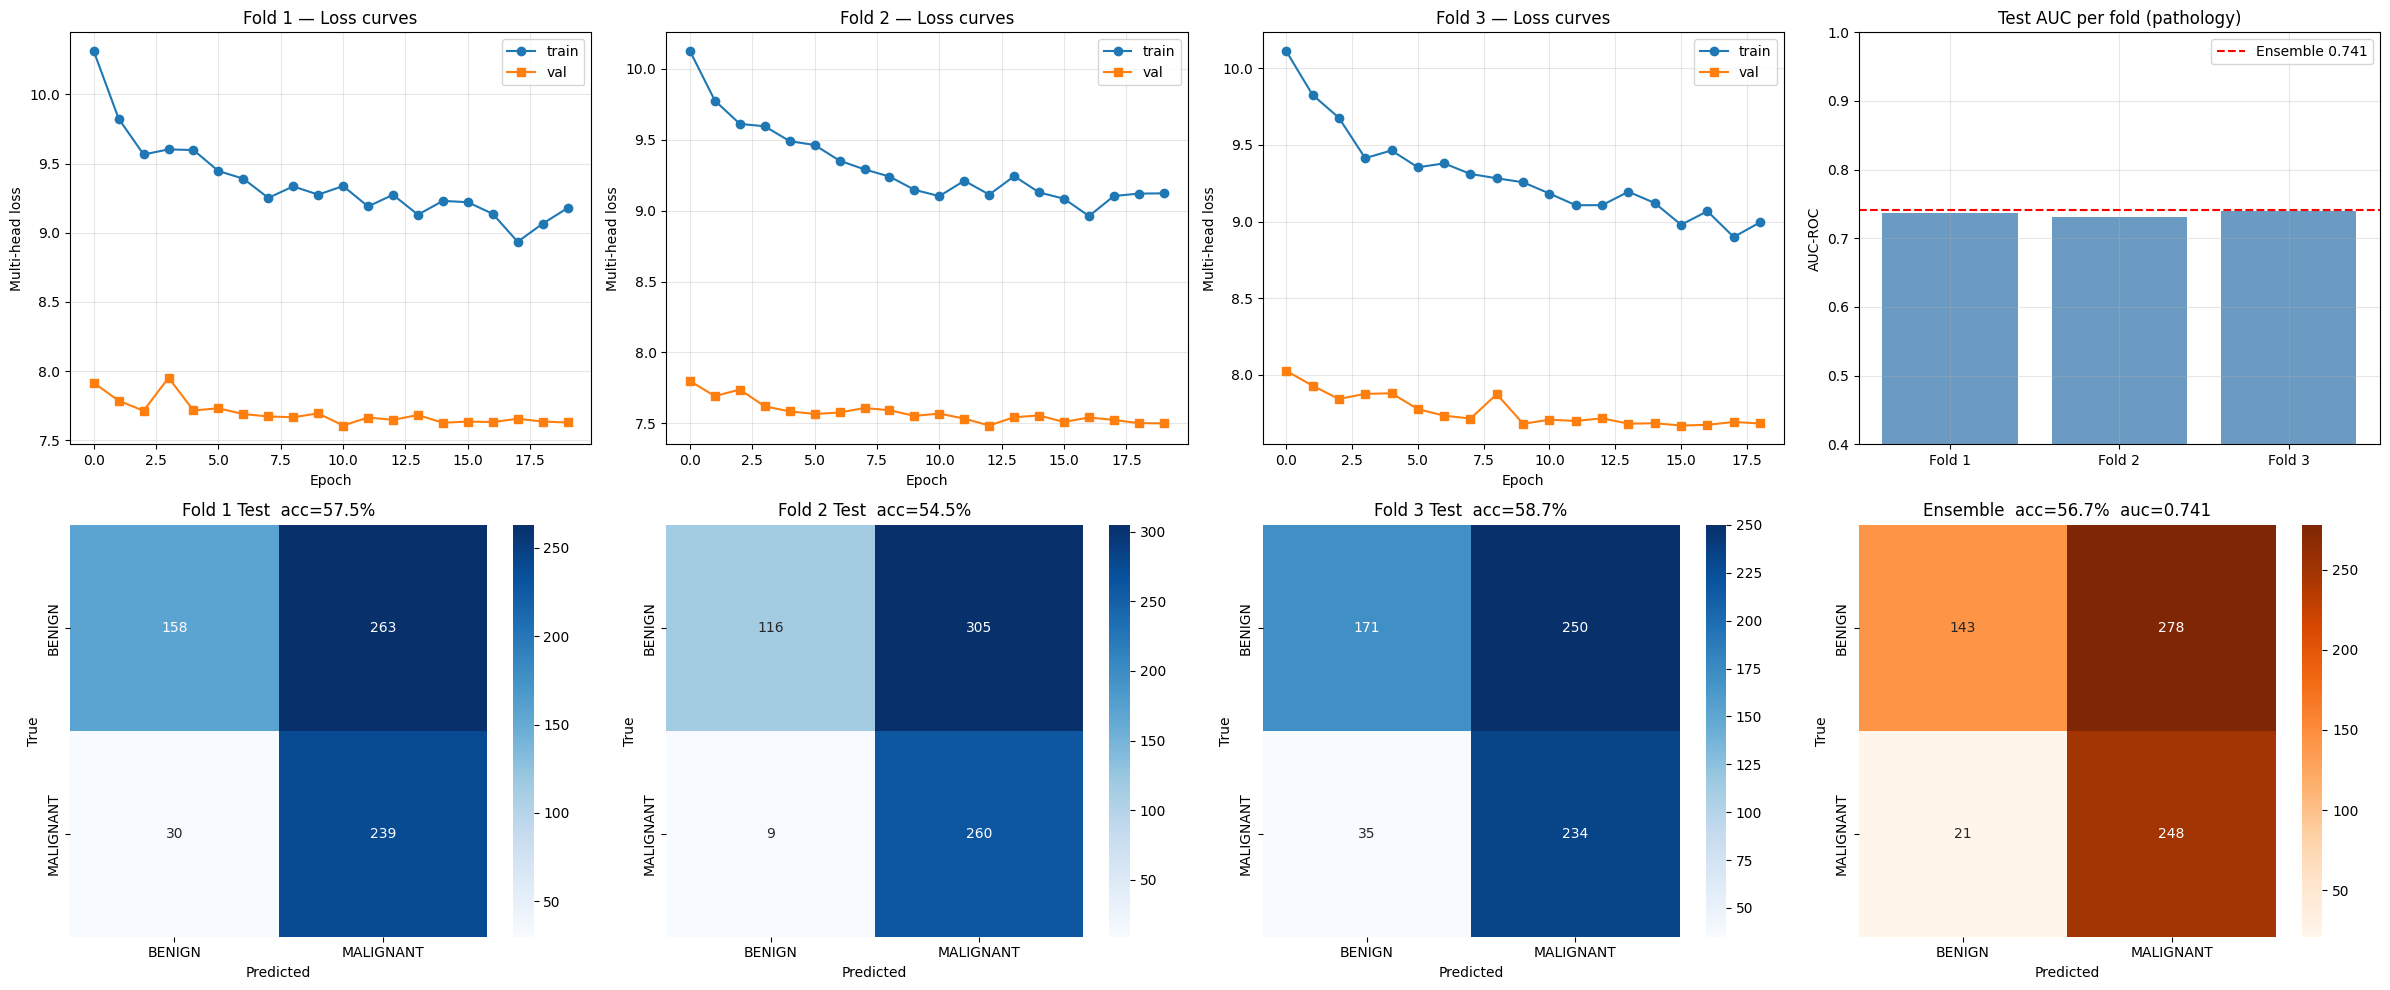

Saved → ./output/kfold_results.png


In [ ]:
fig, axes = plt.subplots(2, K + 1, figsize=(6 * (K + 1), 10))

for i, (h, r) in enumerate(zip(fold_histories, fold_results)):
    ax = axes[0][i]
    ax.plot(h['train'], marker='o', label='train')
    ax.plot(h['val'],   marker='s', label='val')
    ax.set(title=f"Fold {r['fold']} — Loss curves",
           xlabel='Epoch', ylabel='Multi-head loss')
    ax.legend(); ax.grid(alpha=0.3)

ax_bar = axes[0][K]
fold_labels = [f"Fold {r['fold']}" for r in fold_results]
ax_bar.bar(fold_labels, test_aucs, color='steelblue', alpha=0.8)
ax_bar.axhline(ens_auc, color='red', linestyle='--', label=f'Ensemble {ens_auc:.3f}')
ax_bar.set(title='Test AUC per fold (pathology)', ylabel='AUC-ROC', ylim=(0.4, 1.0))
ax_bar.legend(); ax_bar.grid(alpha=0.3)

for i, r in enumerate(fold_results):
    ax = axes[1][i]
    sns.heatmap(r['test']['cm'], annot=True, fmt='d', cmap='Blues',
                xticklabels=['BENIGN', 'MALIGNANT'],
                yticklabels=['BENIGN', 'MALIGNANT'], ax=ax)
    ax.set(title=f"Fold {r['fold']} Test  acc={r['test']['acc']*100:.1f}%",
           xlabel='Predicted', ylabel='True')

sns.heatmap(ens_cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['BENIGN', 'MALIGNANT'],
            yticklabels=['BENIGN', 'MALIGNANT'], ax=axes[1][K])
axes[1][K].set(title=f"Ensemble  acc={ens_acc*100:.1f}%  auc={ens_auc:.3f}",
               xlabel='Predicted', ylabel='True')

plt.tight_layout()
plt.savefig(f'{SAVE_DIR}/kfold_results.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {SAVE_DIR}/kfold_results.png")

## 13 — Predict all 6 fields on new images

Drop your mammography `.jpg` files into `./new_images/` then run this cell.

In [ ]:
BIRADS_DESC = {
    0: "Incomplete — additional imaging needed",
    1: "Negative — no abnormality found",
    2: "Benign finding",
    3: "Probably benign — short-interval follow-up suggested",
    4: "Suspicious — biopsy should be considered",
    5: "Highly suggestive of malignancy",
    6: "Known biopsy-proven malignancy",
}

DENSITY_DESC = {
    0: "Almost entirely fatty",
    1: "Scattered fibroglandular densities",
    2: "Heterogeneously dense",
    3: "Extremely dense",
}


@torch.no_grad()
def predict_image(image_path: str) -> dict:
    """
    Run all 6 heads on a single image using the ensemble of K fold models.
    Returns a dict with predicted class and confidence for each field.
    """
    results = {head: [] for head in HEAD_WEIGHTS}
    pathology_probs = []

    for fold in range(1, K + 1):
        model = build_model()
        ckpt_path = f'{SAVE_DIR}/fold_{fold}/best_model.pt'
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
        model.eval()

        try:
            image = Image.open(image_path).convert('RGB')
        except Exception as e:
            print(f"  Cannot open {image_path}: {e}")
            return None

        inputs = processor(images=image, return_tensors='pt').to(DEVICE)
        outputs = model(inputs['pixel_values'])

        for head in HEAD_WEIGHTS:
            probs = F.softmax(outputs[head], dim=-1).cpu().numpy()[0]
            results[head].append(probs)

        pathology_probs.append(
            F.softmax(outputs['pathology'], dim=-1).cpu().numpy()[0][1]
        )
        del model
        torch.cuda.empty_cache()

    # Ensemble: average probabilities across folds
    def ensemble_head(head):
        avg_probs = np.mean(results[head], axis=0)
        pred_idx  = int(avg_probs.argmax())
        confidence = float(avg_probs.max())
        return pred_idx, confidence, avg_probs

    path_idx, path_conf, _ = ensemble_head('pathology')
    asmt_idx, asmt_conf, _ = ensemble_head('assessment')
    subt_idx, subt_conf, _ = ensemble_head('subtlety')
    dens_idx, dens_conf, _ = ensemble_head('density')
    shpe_idx, shpe_conf, _ = ensemble_head('shape')
    marg_idx, marg_conf, _ = ensemble_head('margins')

    # Decode predictions
    pathology_label = 'MALIGNANT' if path_idx == 1 else 'BENIGN'
    prob_malignant  = float(np.mean(pathology_probs))

    # Reverse-encode ordinal fields
    birads_val   = list(ASSESSMENT_MAP.keys())[asmt_idx] if asmt_idx < 7 else '?'
    subtlety_val = list(SUBTLETY_MAP.keys())[subt_idx]   if subt_idx < 5 else '?'
    density_val  = list(DENSITY_MAP.keys())[dens_idx]    if dens_idx < 4 else '?'

    shape_label   = le_shape.classes_[shpe_idx]   if shpe_idx < N_SHAPE   else 'unknown'
    margins_label = le_margins.classes_[marg_idx] if marg_idx < N_MARGINS else 'unknown'

    return {
        'image_path'     : image_path,
        'pathology'      : pathology_label,
        'prob_malignant' : round(prob_malignant, 4),
        'prob_benign'    : round(1 - prob_malignant, 4),
        'assessment'     : birads_val,
        'assessment_desc': BIRADS_DESC.get(int(birads_val), ''),
        'subtlety'       : subtlety_val,
        'breast_density' : density_val,
        'density_desc'   : DENSITY_DESC.get(dens_idx, ''),
        'mass_shape'     : shape_label,
        'mass_margins'   : margins_label,
        'path_confidence': round(path_conf, 4),
        'asmt_confidence': round(asmt_conf, 4),
    }


# ── Run on all images in new_images/ ─────────────────────────────────────
NEW_IMAGES_DIR = './new_images'
predictions = []

img_files = list(Path(NEW_IMAGES_DIR).glob('*.jpg')) + \
            list(Path(NEW_IMAGES_DIR).glob('*.png'))

if not img_files:
    print("No images found in ./new_images/ — add .jpg or .png files and re-run.")
else:
    print(f"Found {len(img_files)} image(s). Running ensemble prediction...\n")
    for img_file in img_files:
        print(f"Processing: {img_file.name}")
        result = predict_image(str(img_file))
        if result:
            predictions.append(result)
            print(f"  Pathology : {result['pathology']} (p={result['prob_malignant']:.3f})")
            print(f"  BI-RADS   : {result['assessment']} — {result['assessment_desc']}")
            print(f"  Shape     : {result['mass_shape']}")
            print(f"  Margins   : {result['mass_margins']}")
            print()

    predictions_df = pd.DataFrame(predictions)
    predictions_df.to_csv(f'{SAVE_DIR}/new_predictions.csv', index=False)
    print(f"Saved {len(predictions)} predictions → {SAVE_DIR}/new_predictions.csv")

No images found in ./new_images/ — add .jpg or .png files and re-run.


## 14 — Generate structured clinical HTML report

In [ ]:
def generate_report_html(predictions: list) -> str:
    """
    Generate a radiologist-style HTML report for each predicted image.
    """
    if not predictions:
        return "<p>No predictions to report.</p>"

    report_date = datetime.now().strftime('%Y-%m-%d %H:%M')
    cases_html  = ""

    for i, p in enumerate(predictions, 1):
        img_name    = Path(p['image_path']).name
        is_mal      = p['pathology'] == 'MALIGNANT'
        path_color  = '#c0392b' if is_mal else '#1a7a4a'
        path_bg     = '#fff0f0' if is_mal else '#f0fff4'
        birads_num  = int(p['assessment']) if str(p['assessment']).isdigit() else 4
        impression  = (
            'Highly suspicious for malignancy. Tissue sampling recommended.'
            if birads_num >= 4 else
            'Probably benign. Short-interval follow-up recommended.'
            if birads_num == 3 else
            'Benign finding. Routine screening recommended.'
        )

        cases_html += f"""
        <div class="case" style="margin-bottom:40px;page-break-inside:avoid">
          <div class="case-header" style="background:#f8f9fa;border-left:4px solid {path_color};
               padding:12px 16px;border-radius:0 8px 8px 0;margin-bottom:16px">
            <span style="font-size:16px;font-weight:600">Case {i} — {img_name}</span>
            <span style="float:right;background:{path_bg};color:{path_color};
                         padding:4px 12px;border-radius:99px;font-weight:600;font-size:13px">
              {p['pathology']}
            </span>
          </div>

          <table style="width:100%;border-collapse:collapse;font-size:14px">
            <tr style="background:#f5f5f5">
              <th colspan="2" style="padding:8px 12px;text-align:left;
                  border-bottom:2px solid #ddd;font-size:13px;letter-spacing:.5px">
                CLINICAL FINDINGS
              </th>
            </tr>
            <tr>
              <td style="padding:8px 12px;color:#555;width:35%">Breast density</td>
              <td style="padding:8px 12px"><b>Category {p['breast_density']}</b> — {p['density_desc']}</td>
            </tr>
            <tr style="background:#fafafa">
              <td style="padding:8px 12px;color:#555">Lesion type</td>
              <td style="padding:8px 12px">Mass</td>
            </tr>
            <tr>
              <td style="padding:8px 12px;color:#555">Mass shape</td>
              <td style="padding:8px 12px">{p['mass_shape'].replace('-', ' ').title()}</td>
            </tr>
            <tr style="background:#fafafa">
              <td style="padding:8px 12px;color:#555">Mass margins</td>
              <td style="padding:8px 12px">{p['mass_margins'].replace('-', ' ').title()}</td>
            </tr>
            <tr>
              <td style="padding:8px 12px;color:#555">Subtlety</td>
              <td style="padding:8px 12px">{p['subtlety']} / 5</td>
            </tr>
            <tr style="background:#f5f5f5">
              <th colspan="2" style="padding:8px 12px;text-align:left;
                  border-bottom:2px solid #ddd;border-top:2px solid #ddd;
                  font-size:13px;letter-spacing:.5px">
                ASSESSMENT
              </th>
            </tr>
            <tr>
              <td style="padding:8px 12px;color:#555">BI-RADS category</td>
              <td style="padding:8px 12px">
                <b>Category {p['assessment']}</b> — {p['assessment_desc']}
              </td>
            </tr>
            <tr style="background:#fafafa">
              <td style="padding:8px 12px;color:#555">Pathology</td>
              <td style="padding:8px 12px;font-weight:600;color:{path_color}">{p['pathology']}</td>
            </tr>
            <tr>
              <td style="padding:8px 12px;color:#555">P(Malignant)</td>
              <td style="padding:8px 12px">{p['prob_malignant']:.1%} &nbsp;|
                P(Benign) {p['prob_benign']:.1%}</td>
            </tr>
            <tr style="background:#f5f5f5">
              <th colspan="2" style="padding:8px 12px;text-align:left;
                  border-bottom:2px solid #ddd;border-top:2px solid #ddd;
                  font-size:13px;letter-spacing:.5px">
                IMPRESSION
              </th>
            </tr>
            <tr>
              <td colspan="2" style="padding:10px 12px;font-style:italic">{impression}</td>
            </tr>
          </table>
          <p style="font-size:11px;color:#999;margin-top:8px">
            Model confidence — Pathology: {p['path_confidence']:.1%} &nbsp;|
            BI-RADS: {p['asmt_confidence']:.1%} &nbsp;|
            Generated by CLIP multi-output model (CBIS-DDSM fine-tuned)
          </p>
        </div>"""

    html = f"""<!DOCTYPE html>
<html lang="en"><head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Mammography Clinical Report</title>
<style>
  body {{ font-family: 'Segoe UI', Arial, sans-serif; max-width: 900px;
          margin: 40px auto; padding: 0 24px; color: #222; }}
  h1   {{ font-size: 22px; margin-bottom: 4px; }}
  .meta {{ font-size: 13px; color: #666; margin-bottom: 32px;
           padding-bottom: 16px; border-bottom: 1px solid #eee; }}
  table {{ border-bottom: 1px solid #eee; margin-bottom: 8px; }}
  @media print {{ .case {{ page-break-inside: avoid; }} }}
</style>
</head><body>
<h1>Mammography Classification Report</h1>
<div class="meta">
  Model: CLIP ViT-B/32 fine-tuned on CBIS-DDSM (mass + calcification) &nbsp;|&nbsp;
  Cross-validation: {K}-fold &nbsp;|&nbsp;
  Ensemble: averaged probabilities &nbsp;|&nbsp;
  Generated: {report_date}
</div>
{cases_html}
<p style="font-size:11px;color:#bbb;margin-top:40px;border-top:1px solid #eee;padding-top:12px">
  DISCLAIMER: This report is generated by an AI model for research purposes only.
  It should not be used as a substitute for professional medical diagnosis.
</p>
</body></html>"""
    return html


# Generate and save the report
if predictions:
    report_html  = generate_report_html(predictions)
    report_path  = f'{SAVE_DIR}/clinical_report.html'
    with open(report_path, 'w', encoding='utf-8') as f:
        f.write(report_html)
    print(f"Clinical report saved → {report_path}")
    print(f"Open it in any browser (double-click the file).")
else:
    print("No predictions found. Run cell 13 first with images in ./new_images/")

No predictions found. Run cell 13 first with images in ./new_images/


## 15 — (Optional) Generate report for the test set predictions

In [ ]:
# Save ensemble test set predictions to CSV
pred_df = pd.DataFrame({
    'image_path'    : [row['image_path'] for _, row in test_df.iterrows()
                       if len(true_labels) > 0][:len(true_labels)],
    'true_pathology': ['BENIGN' if l == 0 else 'MALIGNANT' for l in true_labels],
    'pred_pathology': ['BENIGN' if p == 0 else 'MALIGNANT' for p in ensemble_preds],
    'prob_malignant': ensemble_probs,
    'correct'       : [l == p for l, p in zip(true_labels, ensemble_preds)],
})

for fold_idx, probs in enumerate(all_test_probs, start=1):
    pred_df[f'fold{fold_idx}_prob_malignant'] = probs

pred_df.to_csv(f'{SAVE_DIR}/ensemble_predictions.csv', index=False)

print(f"Saved to {SAVE_DIR}/")
print(f"  fold_N/best_model.pt         — per-fold model weights")
print(f"  kfold_results.png            — training curves + confusion matrices")
print(f"  ensemble_predictions.csv     — test set predictions")
print(f"  new_predictions.csv          — predictions on your new images")
print(f"  clinical_report.html         — structured clinical report")

Saved to ./output/
  fold_N/best_model.pt         — per-fold model weights
  kfold_results.png            — training curves + confusion matrices
  ensemble_predictions.csv     — test set predictions
  new_predictions.csv          — predictions on your new images
  clinical_report.html         — structured clinical report
